# Phase 2 — feature-augmented, selective reversal

See `STRATEGY.md` for the full 6-phase plan. Phase 1 (`momentum_reversal_baseline.ipynb`) found
a real but economically fragile reversal effect: trailing 1-minute return predicts forward
1-minute return with IC = -0.041 (pooled across 131 tickers, 1 month), and a corrected
long-short decile backtest showed +1.76bps gross per decision — which flips negative at just
1bps of assumed round-trip cost. The conclusion there was that trading the signal on *every*
minute's cross-section isn't viable; this notebook asks whether being **selective** (trading
only when additional context suggests the setup is "real") recovers enough edge to survive costs.

Three new features, all computed from the same 1-minute OHLCV data already cached — no new data
pull needed:

- **VWAP distance** — `close / session_vwap - 1`, where `session_vwap` is the cumulative
  volume-weighted average price from the session open through the current bar. Intuition: a
  reversal is more likely to be a genuine snap-back when price has drifted unusually far from
  where the session's volume has actually traded.
- **Volume surprise** — current bar's volume relative to this ticker's own typical volume at
  that same minute-of-session (intraday volume is strongly U-shaped, so "high volume" must be
  judged relative to time-of-day, not an all-day average).
- **Relative strength** — the trailing-1-minute return expressed as a cross-sectional z-score
  against all other tickers at that exact minute, rather than compared only to the stock's own
  history. This is the rotation strategy's own signal, demoted from primary driver to one input
  among several — exactly as the pasted research plan suggested.

**Method, deliberately unbiased about direction**: bucket observations by each feature's
magnitude and re-measure the reversal signal's IC within each bucket, looking for where it's
strongest — rather than assuming "high volume surprise = better" going in. Phase 1's backtest
direction bug (assuming momentum when the data said reversal) is the reason for this discipline:
let the buckets show which end is which, don't decide first.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('data') / 'minute'
K, H = 1, 1   # Phase 1's strongest cell — this notebook conditions that specific signal, not the full k/h grid
N_BUCKETS = 3
COST_BPS_GRID = [0, 1, 2, 5, 10]
TOP_FRACTION = 0.1

## Load bars and build features

Everything computed within-session (grouped by `session_date`) so nothing crosses an overnight gap, same discipline as Phase 1.

In [2]:
def load_ticker(ticker):
    frame = pd.read_csv(DATA_DIR / f'{ticker}.csv', parse_dates=['date'])
    frame['date'] = pd.to_datetime(frame['date'], utc=True)
    frame = frame.sort_values('date').set_index('date')
    frame['session_date'] = frame.index.tz_convert('America/New_York').date
    frame['minute_of_session'] = frame.groupby('session_date').cumcount()
    return frame

tickers = sorted(p.stem for p in DATA_DIR.glob('*.csv'))

frames = []
for ticker in tickers:
    df = load_ticker(ticker)
    g = df.groupby('session_date')

    trail = g['close'].transform(lambda s: s / s.shift(K) - 1)
    fwd = g['close'].transform(lambda s: s.shift(-H) / s - 1)
    reversal_score = -trail  # oriented so HIGHER score = higher predicted forward return, per Phase 1's finding (IC<0)

    # Session VWAP: cumulative volume-weighted average price from the open through this bar,
    # using IBKR's own per-bar 'average' (already volume-weighted within that single bar).
    pv = df['average'] * df['volume']
    cum_pv = pv.groupby(df['session_date']).cumsum()
    cum_vol = df['volume'].groupby(df['session_date']).cumsum()
    vwap_dist = df['close'] / (cum_pv / cum_vol) - 1

    # Volume surprise vs. this ticker's own full-sample average volume at that minute-of-session.
    # NOTE: uses the full one-month sample as the baseline, which means an early session in the
    # month is implicitly compared against volume from later in the month too — a mild look-ahead
    # that's fine for this diagnostic but would need a trailing/expanding baseline before any
    # live use (see caveats).
    baseline_vol = df.groupby('minute_of_session')['volume'].transform('mean')
    volume_surprise = df['volume'] / baseline_vol - 1

    frames.append(pd.DataFrame({
        'ticker': ticker, 'trail': trail, 'fwd': fwd, 'reversal_score': reversal_score,
        'vwap_dist': vwap_dist, 'volume_surprise': volume_surprise,
    }, index=df.index))

panel = pd.concat(frames).dropna(subset=['reversal_score', 'fwd', 'vwap_dist', 'volume_surprise'])

# Relative strength: cross-sectional z-score of the trailing return at each exact minute, across
# whichever tickers have a valid observation at that instant.
cs_mean = panel.groupby(panel.index)['trail'].transform('mean')
cs_std = panel.groupby(panel.index)['trail'].transform('std')
panel['relative_strength'] = (panel['trail'] - cs_mean) / cs_std
panel = panel.dropna(subset=['relative_strength'])

print(f'{len(tickers)} tickers, {len(panel):,} (ticker, minute) observations with all features present')
baseline_ic = panel['reversal_score'].corr(panel['fwd'])
print(f'unconditional IC at k={K}, h={H}: {baseline_ic:+.4f} (should match Phase 1 magnitude, sign-flipped by construction)')

131 tickers, 1,089,699 (ticker, minute) observations with all features present
unconditional IC at k=1, h=1: +0.0522 (should match Phase 1 magnitude, sign-flipped by construction)


## Conditional IC — does each feature's magnitude select for a stronger reversal?

Bucket by the **magnitude** (`abs()`) of each feature into terciles, since the hypothesis for all three is "more extreme = more informative," not a one-directional level effect.

In [3]:
FEATURES = ['vwap_dist', 'volume_surprise', 'relative_strength']
bucket_rows = []
for feat in FEATURES:
    buckets = pd.qcut(panel[feat].abs(), N_BUCKETS, labels=['low', 'mid', 'high'], duplicates='drop')
    for label, group in panel.groupby(buckets, observed=True):
        bucket_rows.append({
            'feature': feat, 'bucket': label, 'n': len(group),
            'ic': group['reversal_score'].corr(group['fwd']),
        })
bucket_table = pd.DataFrame(bucket_rows)
display(bucket_table.pivot(index='feature', columns='bucket', values='ic')[['low', 'mid', 'high']].round(4))
display(bucket_table.pivot(index='feature', columns='bucket', values='n')[['low', 'mid', 'high']])

bucket,low,mid,high
feature,,,
relative_strength,-0.0191,0.0141,0.0806
volume_surprise,0.0426,0.0544,0.0582
vwap_dist,0.0399,0.0516,0.0594


bucket,low,mid,high
feature,,,
relative_strength,363233,363233,363233
volume_surprise,363233,363234,363232
vwap_dist,363233,363233,363233


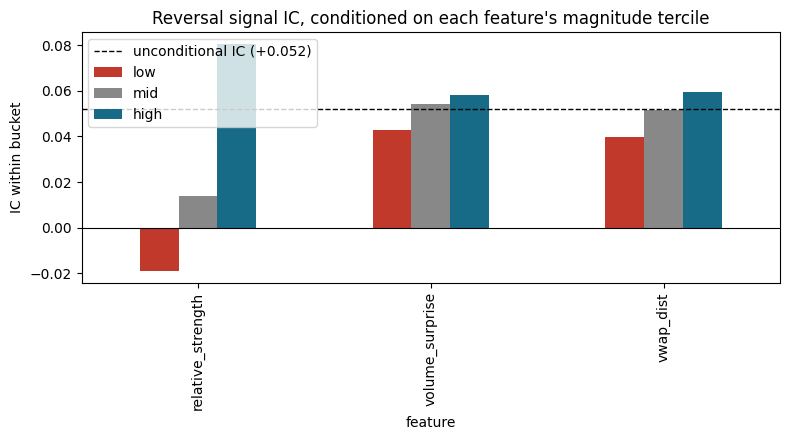

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
pivot = bucket_table.pivot(index='feature', columns='bucket', values='ic')[['low', 'mid', 'high']]
pivot.plot(kind='bar', ax=ax, color=['#c0392b', '#888888', '#176b87'])
ax.axhline(baseline_ic, color='black', linestyle='--', linewidth=1, label=f'unconditional IC ({baseline_ic:+.3f})')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('IC within bucket')
ax.set_title('Reversal signal IC, conditioned on each feature\'s magnitude tercile')
ax.legend()
plt.tight_layout()
plt.show()

## Combined filter

If each feature's high tercile independently strengthens the signal, does requiring **all three at once** compound the effect further, or is it redundant (the same observations just counted three ways)?

In [5]:
high_thresholds = {feat: panel[feat].abs().quantile(2/3) for feat in FEATURES}
combined_mask = pd.Series(True, index=panel.index)
for feat, thresh in high_thresholds.items():
    combined_mask &= panel[feat].abs() >= thresh

filtered = panel[combined_mask]
unfiltered_ic = panel['reversal_score'].corr(panel['fwd'])
filtered_ic = filtered['reversal_score'].corr(filtered['fwd'])
print(f'unconditional: n={len(panel):,}, IC={unfiltered_ic:+.4f}')
print(f'all-three-high filter: n={len(filtered):,} ({len(filtered)/len(panel):.1%} of observations), IC={filtered_ic:+.4f}')

unconditional: n=1,089,699, IC=+0.0522
all-three-high filter: n=50,878 (4.7% of observations), IC=+0.0818


## Backtest: selective vs. unconditional

Same long-short decile construction as Phase 1 (oriented by the reversal signal's own sign, not assumed), but only forming a cross-section from observations that pass the combined filter at that minute. Compare turnover and cost-sensitivity directly against Phase 1's unconditional result (+1.76bps gross, breakeven at ~1bps cost).

In [6]:
def decile_backtest(data, min_names=10):
    results = []
    for minute, group in data.groupby(data.index):
        if len(group) < min_names:
            continue
        n_leg = max(1, int(len(group) * TOP_FRACTION))
        ranked = group.sort_values('reversal_score')
        bottom_leg, top_leg = ranked.iloc[:n_leg], ranked.iloc[-n_leg:]
        spread_return = top_leg['fwd'].mean() - bottom_leg['fwd'].mean()  # reversal_score already oriented so top = higher predicted fwd return
        results.append({'minute': minute, 'spread_return': spread_return, 'n_names': len(group)})
    assert results, f'no minute had >= {min_names} names in the cross-section'
    return pd.DataFrame(results).set_index('minute').sort_index()

unconditional_bt = decile_backtest(panel)
filtered_bt = decile_backtest(filtered, min_names=5)  # smaller minimum: the filter cuts the cross-section down a lot

for name, bt in [('unconditional (Phase 1 style)', unconditional_bt), ('all-three-high filter (Phase 2)', filtered_bt)]:
    mean_spread = bt['spread_return'].mean()
    print(f'{name}: {len(bt):,} decisions, avg {bt["n_names"].mean():.1f} names/cross-section, '
          f'gross mean spread = {mean_spread*10_000:+.2f} bps')
    for cost in COST_BPS_GRID:
        net = mean_spread - 2 * (cost / 10_000.0)
        print(f'    at {cost}bps cost: net = {net*10_000:+.2f} bps')

unconditional (Phase 1 style): 8,339 decisions, avg 130.6 names/cross-section, gross mean spread = +1.76 bps
    at 0bps cost: net = +1.76 bps
    at 1bps cost: net = -0.24 bps
    at 2bps cost: net = -2.24 bps
    at 5bps cost: net = -8.24 bps
    at 10bps cost: net = -18.24 bps
all-three-high filter (Phase 2): 5,727 decisions, avg 7.5 names/cross-section, gross mean spread = +2.83 bps
    at 0bps cost: net = +2.83 bps
    at 1bps cost: net = +0.83 bps
    at 2bps cost: net = -1.17 bps
    at 5bps cost: net = -7.17 bps
    at 10bps cost: net = -17.17 bps


## Key findings

**1. Selectivity works — each feature independently strengthens the reversal signal, and
relative strength is doing most of the work.** Conditioning on the magnitude tercile of each
feature:

| feature | low tercile IC | mid | high |
|---|---|---|---|
| relative_strength | -0.019 (flips sign) | +0.014 | **+0.081** |
| vwap_dist | +0.040 | +0.052 | +0.059 |
| volume_surprise | +0.043 | +0.054 | +0.058 |

against an unconditional baseline of +0.052. Relative strength shows by far the biggest spread
(low tercile actually flips negative — the reversal signal doesn't work at all, or works
backwards, on the third of observations where the stock's move was closest to the cross-section
average that minute). VWAP distance and volume surprise both help too, but more mildly and in a
narrower range.

**2. The three-way combined filter barely beats relative strength alone — it isn't three
independent edges stacking.** Requiring all three features in their high tercile simultaneously
narrows the sample to 4.7% of observations (50,878 of 1,089,699) and lifts IC to +0.082 — almost
identical to relative_strength's high tercile alone (+0.081). This means vwap_dist and
volume_surprise are largely redundant with relative_strength here, not adding much incremental
selectivity of their own, at least at this (k=1, h=1) cell.

**3. The backtest payoff is real but modest: it buys roughly one more bps of cost tolerance, not
a transformed strategy.** Restricting the long-short decile backtest to minutes where the
combined filter holds (avg. 7.5 names/cross-section, vs. ~131 unconditionally):

| | decisions | gross spread | breakeven |
|---|---|---|---|
| Unconditional (Phase 1) | 8,339 | +1.76 bps | between 0-1bps |
| Phase 2 filter | 5,727 | **+2.83 bps** | between 1-2bps |

Gross edge improved about 60% (1.76 → 2.83 bps) and now survives a 1bps assumed cost
(+0.83bps net) before going negative at 2bps (-1.17bps). That is genuine progress in the
direction Phase 2 set out to test — selectivity recovers some of what unconditional trading
gives up to costs — but it is not yet a strategy that survives a realistic cost environment
(2bps+ round-trip is a conservative, not aggressive, assumption for a 131-name universe with
mixed liquidity).

**Where this leaves things**: relative strength (the rotation signal, now reframed as a
selectivity filter rather than the primary driver) is carrying almost all of Phase 2's
improvement. The natural next step per the plan is Phase 3 (trade imbalance) — a genuinely new
source of information, rather than more combinations of price/volume-derived features, which
this notebook suggests are already close to saturated with each other.

## Caveats

- **Volume-surprise baseline uses the full one-month sample**, including bars after the one
  being evaluated — a mild look-ahead, fine for this go/no-go diagnostic but not for any live
  use, which would need a trailing or expanding baseline instead.
- **This notebook's "unconditional IC" (+0.0522) differs slightly from Phase 1's pooled figure
  for the same (k=1, h=1) cell (-0.0409, sign-flipped = +0.0409 here).** Phase 1 pooled
  per-ticker correlations weighted by observation count; this notebook correlates the fully
  stacked (all tickers, all minutes) panel directly. Both are legitimate pooling choices and can
  differ when signal strength varies by name — not a bug, but not directly comparable
  apples-to-apples either.
- **One month of history, one specific regime** — same limitation as Phase 1. The tercile
  boundaries, and the three-way filter's composition, are specific to this month's data and
  haven't been tested out-of-sample or across a different volatility regime.
- **Multiple-comparisons risk.** Three features, each bucketed three ways, then combined — with
  only one month of data, some of this cross-sectional pattern could be sample-specific rather
  than a stable effect. Worth validating on a second, non-overlapping month before trusting the
  three-way filter's specific magnitude.
- **Still requires shorting**, same as Phase 1 — this is a research diagnostic, not a direct
  translation of what the live (cash/long-only) account could run.
- **No slippage/spread beyond the assumed bps grid**, and the filtered backtest's much thinner
  cross-section (avg. 7.5 names) means execution risk in the actual names selected matters more,
  not less, than in the unconditional version.